# Version finale - 1. Découpage des lames en patchs

Ce notebook ne contient pas le découpage lui-même : il prépare, lance et compare. Le travail lourd est dans les scripts du dossier `version_finale` :

- `camelyon_data.py`
- `extract_patches.py`
- `parametres_decoupage.py`

Plan :
1. Installation et imports
2. Index des lames et sélection
3. Taille des pixels par centre
4. Comparaison des options pour la détection de tissu
5. Lancement des variantes
6. Comparaison des variantes d'étiquetage

## 1. Installation et imports

In [ ]:
import os
import sys
from pathlib import Path

# On se place dans version_finale/ pour que les chemins soient les mêmes que pour les commandes du terminal
if not Path("extract_patches.py").exists():
    os.chdir("..")
sys.path.append(".")
print("Dossier de travail :", Path.cwd())

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import camelyon_data as cd
import extract_patches as ep
import parametres_decoupage as pdc

Dossier de travail : c:\Users\joell\projets\projet-camelyon17\version_finale


## 2. Index des lames et sélection

`build_remote_index` télécharge seulement les annotations XML et `stages.csv` (léger) et liste les lames qui restent sur AWS.

In [2]:
index = cd.build_remote_index()
print(len(index), "lames,", index.annotated.sum(), "annotées")
index.head()

  50 annotations XML dans data\CAMELYON17\annotations | labels : OK
1000 lames, 50 annotées


,slide,tif_path,xml_path,patient,node,center,slide_label,pN_stage,annotated
0,patient_000_node_0,s3://camelyon-dataset/CAMELYON17/images/patien...,NaN,patient_000,0,0.0,negative,pN0,False
1,patient_000_node_1,s3://camelyon-dataset/CAMELYON17/images/patien...,NaN,patient_000,1,0.0,negative,pN0,False
2,patient_000_node_2,s3://camelyon-dataset/CAMELYON17/images/patien...,NaN,patient_000,2,0.0,negative,pN0,False
3,patient_000_node_3,s3://camelyon-dataset/CAMELYON17/images/patien...,NaN,patient_000,3,0.0,negative,pN0,False
4,patient_000_node_4,s3://camelyon-dataset/CAMELYON17/images/patien...,NaN,patient_000,4,0.0,negative,pN0,False


Règles fixées pour la sélection :
- On ne garde que des lames dont on connaît la vérité soit les lames annotées et les lames négatives. 
- Une patiente n'est que dans un seul set. 
- La graine fixe donne toujours le même tirage.

- **Test :** patientes entières choisies en premier
  - 1 patiente complète (lames tumorales annotées) avec métastases par centre en variant les stades
  - 2 patientes pN0 de centres différents (complètes d'office car aucune tumeur) pour mesurer les fausses alertes
  - 1 patiente pN2 (aucune n'est complète)
- **Validation** : par centre : 1 lame annotée + 1 lame négative
- **Entraînement** : par centre : 5 lames annotées + 2 lames négatives

Les fonctions de la sélection :
- `completes` : la liste des patientes avec vérité complète.
- `selectionner` : choisit d'abord le test (patientes entières), puis centre par centre la validation et l'entraînement parmi les patientes restantes.
- `verifier` : affiche le nombre de lames par centre et par set et vérifie qu'aucune patiente n'est dans deux sets puis résume le test

In [ ]:
STADES_POSITIFS = ["pN0(i+)", "pN1mi", "pN1"]   # stades possibles des patientes complètes avec métastases


def completes(df):
    # Patientes "à vérité complète" : toutes leurs lames avec métastases (classe autre que negative) sont annotées.
    # On connaît alors la tumeur au pixel près sur leurs 5 lames (les lames négatives n'en ont pas).
    positives = df[df.slide_label != "negative"]
    return set(df.patient) - set(positives[~positives.annotated].patient)


def selectionner(df, n_annotees=5, n_negatives=2, n_val_annotees=1, n_val_negatives=1, n_test_pN0=2, test_pN2=True, seed=0):
    # df = l'index des lames (cd.build_remote_index())
    rng = np.random.default_rng(seed) # Générateur de hasard (graine fixe : toujours la même sélection)
    df = df[df.pN_stage.notna()].copy() # Seules les patientes dont on connaît le stade (0 à 99)
    choix = [] # Les lames choisies : (slide, set, raison)
    pris = set() # Patientes déjà utilisées (une patiente n'est que dans un set)

    def tirer(lames, n):
        # n lames tirées au hasard
        return lames.iloc[rng.permutation(len(lames))[:n]]

    def ajouter_patiente(p, raison):
        # Toute la patiente (ses 5 lames) va dans le test
        for s in df[df.patient == p].slide:
            choix.append((s, "test", raison))
        pris.add(p)

    # TEST
    comp = completes(df)
    stade = df.groupby("patient").pN_stage.first()
    centre = df.groupby("patient").center.first()

    # Une patiente complète avec métastases par centre, en variant les stades :
    # à chaque centre, on prend parmi ses candidates celles du stade le moins utilisé jusque-là
    utilises = {s: 0 for s in STADES_POSITIFS}
    for c in sorted(df.center.dropna().unique()):
        cand = sorted(p for p in comp if centre[p] == c and stade[p] in STADES_POSITIFS)
        if not cand:
            continue
        moins = min(utilises[stade[p]] for p in cand)
        cand = [p for p in cand if utilises[stade[p]] == moins]
        p = cand[rng.integers(len(cand))]
        utilises[stade[p]] += 1
        ajouter_patiente(p, f"test complet ({stade[p]})")

    # Des patientes pN0 dans des centres différents
    centres_pN0 = rng.permutation(sorted(df.center.dropna().unique()))[:n_test_pN0]
    for c in centres_pN0:
        cand = sorted(p for p in stade.index if stade[p] == "pN0" and centre[p] == c and p not in pris)
        ajouter_patiente(cand[rng.integers(len(cand))], "test complet (pN0)")

    # Une patiente pN2 : celle qui a le plus de lames positives annotées
    if test_pN2:
        pN2 = df[(df.pN_stage == "pN2") & ~df.patient.isin(pris)]
        nb = pN2[pN2.annotated & (pN2.slide_label != "negative")].groupby("patient").size()
        cand = sorted(nb[nb == nb.max()].index) if len(nb) else sorted(pN2.patient.unique())
        ajouter_patiente(cand[rng.integers(len(cand))], "test partiel (pN2)")

    # VALIDATION puis ENTRAINEMENT, centre par centre parmi les patientes restantes
    for c in sorted(df.center.dropna().unique()):
        reste = df[(df.center == c) & ~df.patient.isin(pris)]

        # Validation : lame(s) annotée(s) puis lame(s) négative(s), chacune d'une patiente qu'on retire ensuite
        for _ in range(n_val_annotees):
            v = tirer(reste[reste.annotated], 1)
            choix += [(s, "validation", "annotée") for s in v.slide]
            reste = reste[~reste.patient.isin(v.patient)]
            pris |= set(v.patient)
        for _ in range(n_val_negatives):
            v = tirer(reste[(reste.slide_label == "negative") & ~reste.annotated], 1)
            choix += [(s, "validation", "négative") for s in v.slide]
            reste = reste[~reste.patient.isin(v.patient)]
            pris |= set(v.patient)

        # Entrainement : lames annotées + lames négatives des patientes restantes
        for s in tirer(reste[reste.annotated], n_annotees).slide:
            choix.append((s, "entrainement", "annotée"))
        for s in tirer(reste[(reste.slide_label == "negative") & ~reste.annotated], n_negatives).slide:
            choix.append((s, "entrainement", "négative"))

    sel = pd.DataFrame(choix, columns=["slide", "set", "raison"])
    infos = df[["slide", "patient", "node", "center", "slide_label", "pN_stage", "annotated"]]
    return sel.merge(infos, on="slide").sort_values(["set", "center", "slide"]).reset_index(drop=True)


def verifier(sel):
    # Petits contrôles : lames par set et par centre, aucune patiente dans deux sets, résumé du test
    print(pd.crosstab(sel.center, sel.set, margins=True))
    sets_par_patiente = sel.groupby("patient").set.nunique()
    fuites = sets_par_patiente[sets_par_patiente > 1]
    print("Patientes dans plusieurs sets :", list(fuites.index) if len(fuites) else "aucune")
    test = sel[sel.set == "test"].groupby("patient").agg(centre=("center", "first"), stade=("pN_stage", "first"),
                                                         raison=("raison", "first"), lames=("slide", "size"),
                                                         annotees=("annotated", "sum"))
    print("\nTest :"); print(test.sort_values("centre"))
    return fuites.empty


In [ ]:
selection = selectionner(index, n_annotees=5, n_negatives=2, n_val_annotees=1, n_val_negatives=1,
                         n_test_pN0=2, test_pN2=True, seed=0)
pas_de_fuite = verifier(selection) # tableau centre x set, contrôle des patientes, résumé du test
selection.groupby(["set", "slide_label"]).size().unstack(fill_value=0)

set     entrainement  test  validation  All
center                                     
0.0                7     5           2   14
1.0                7     5           2   14
2.0                7    10           2   19
3.0                7    10           2   19
4.0                7    10           2   19
All               35    40          10   85
Patientes dans plusieurs sets : aucune

Test :
             centre    stade                  raison  lames  annotees
patient                                                              
patient_012     0.0      pN1      test complet (pN1)      5         1
patient_036     1.0    pN1mi    test complet (pN1mi)      5         1
patient_041     2.0  pN0(i+)  test complet (pN0(i+))      5         1
patient_053     2.0      pN0      test complet (pN0)      5         0
patient_062     3.0      pN2      test partiel (pN2)      5         1
patient_075     3.0      pN1      test complet (pN1)      5         1
patient_086     4.0  pN0(i+)  test comple

slide_label,itc,macro,micro,negative
set,,,,
entrainement,10,8,7,10
test,3,4,3,30
validation,0,2,3,5


In [5]:
# Lames de test : classe de chaque lame et annotation, patiente par patiente
selection[selection.set == "test"][["center", "patient", "pN_stage", "raison", "slide", "slide_label", "annotated"]]

,center,patient,pN_stage,raison,slide,slide_label,annotated
35,0.0,patient_012,pN1,test complet (pN1),patient_012_node_0,macro,True
36,0.0,patient_012,pN1,test complet (pN1),patient_012_node_1,negative,False
37,0.0,patient_012,pN1,test complet (pN1),patient_012_node_2,negative,False
38,0.0,patient_012,pN1,test complet (pN1),patient_012_node_3,negative,False
39,0.0,patient_012,pN1,test complet (pN1),patient_012_node_4,negative,False
40,1.0,patient_036,pN1mi,test complet (pN1mi),patient_036_node_0,negative,False
41,1.0,patient_036,pN1mi,test complet (pN1mi),patient_036_node_1,negative,False
42,1.0,patient_036,pN1mi,test complet (pN1mi),patient_036_node_2,negative,False
43,1.0,patient_036,pN1mi,test complet (pN1mi),patient_036_node_3,micro,True
44,1.0,patient_036,pN1mi,test complet (pN1mi),patient_036_node_4,negative,False


In [ ]:
# Enregistrement : c'est ce fichier que extract_patches.py lit (via la clé "selection" de parametres_decoupage.py)

selection.to_csv(pdc.PARAMETRES["selection"], index=False)

## 3. Taille des pixels par centre

Pour chaque centre :
- On prend une lame qui n’est pas dans le test
- On lit la taille d’un pixel au niveau 0
- Pour les niveaux 0, 1 et 2 on calcule combien de pixels il faut lire pour couvrir 112 µm.

In [17]:
lignes = []
for centre, groupe in selection[selection.set != "test"].groupby("center"):
    lame = index[index.slide == groupe.slide.iloc[0]].iloc[0]
    slide = cd.open_slide(lame.tif_path)
    mpp = cd.taille_pixel_um(slide)
    for niveau in [0, 1, 2]:
        ds = slide.level_downsamples[niveau]
        lignes.append({"centre": centre, "lame": lame.slide, "niveau": niveau, "µm/pixel": round(mpp * ds, 3),
                       "pixels lus pour 112 µm": round(112 / mpp / ds)})
pd.DataFrame(lignes).pivot(index="centre", columns="niveau", values="pixels lus pour 112 µm")

niveau,0,1,2
centre,,,
0.0,461,230,115
1.0,461,230,115
2.0,495,247,124
3.0,461,230,115
4.0,448,224,112


On observe que le centre 2 a des pixels plus petits que les autres et le centre 4 des pixels un peu plus grands.

Si on avait découpé un nombre fixe de pixels (par exemple 224 partout), un patch ne couvrirait pas la même surface de tissu selon le centre. Avec 112 µm fixes, chaque patch couvre la même surface, quel que soit le scanner.

C'est pour ça qu'on découpe à surface fixe (`patch_um` = 112 µm) : le nombre de pixels lus (`taille_lue`) s'adapte à chaque lame puis le patch est remis à 224 pixels.

## 4. Détection du tissu : choix du seuil de saturation


On utilise `detect_purple` (dans `extract_patches.py`) : un pixel est du tissu si
- Sa teinte est rose-violet (H >= 120 ou H <= 10, échelle OpenCV 0 à 180)
- Sa saturation est assez forte (S >= seuil, sur 255)
- il n'est ni trop sombre ni trop clair (50 <= V <= 245)
Ensuite une ouverture et une fermeture 5x5 enlèvent les petits points et bouchent les petits trous.

Comme la coloration est plus ou moins pâle selon les centres, on compare plusieurs seuils de saturation (30, 20, 15, 10) sur une lame par centre, en zoomant sur la zone où baisser le seuil change le plus de choses (vert = tissu gardé).

On cherche le seuil le plus haut qui garde tout le tissu du ganglion sans prendre la graisse ou le fond de la lame. En effet, les métastases se trouvent dans le tissu du ganglion et pas dans la graisse (ni dans le fond, évidemment). Pour le modèle, la vraie difficulté est de distinguer le tissu ganglionnaire sain du tumoral.
Le même filtre de tissu est appliqué à l’entraînement et à la prédiction : le modèle n’a donc jamais à classer la graisse ou le fond.

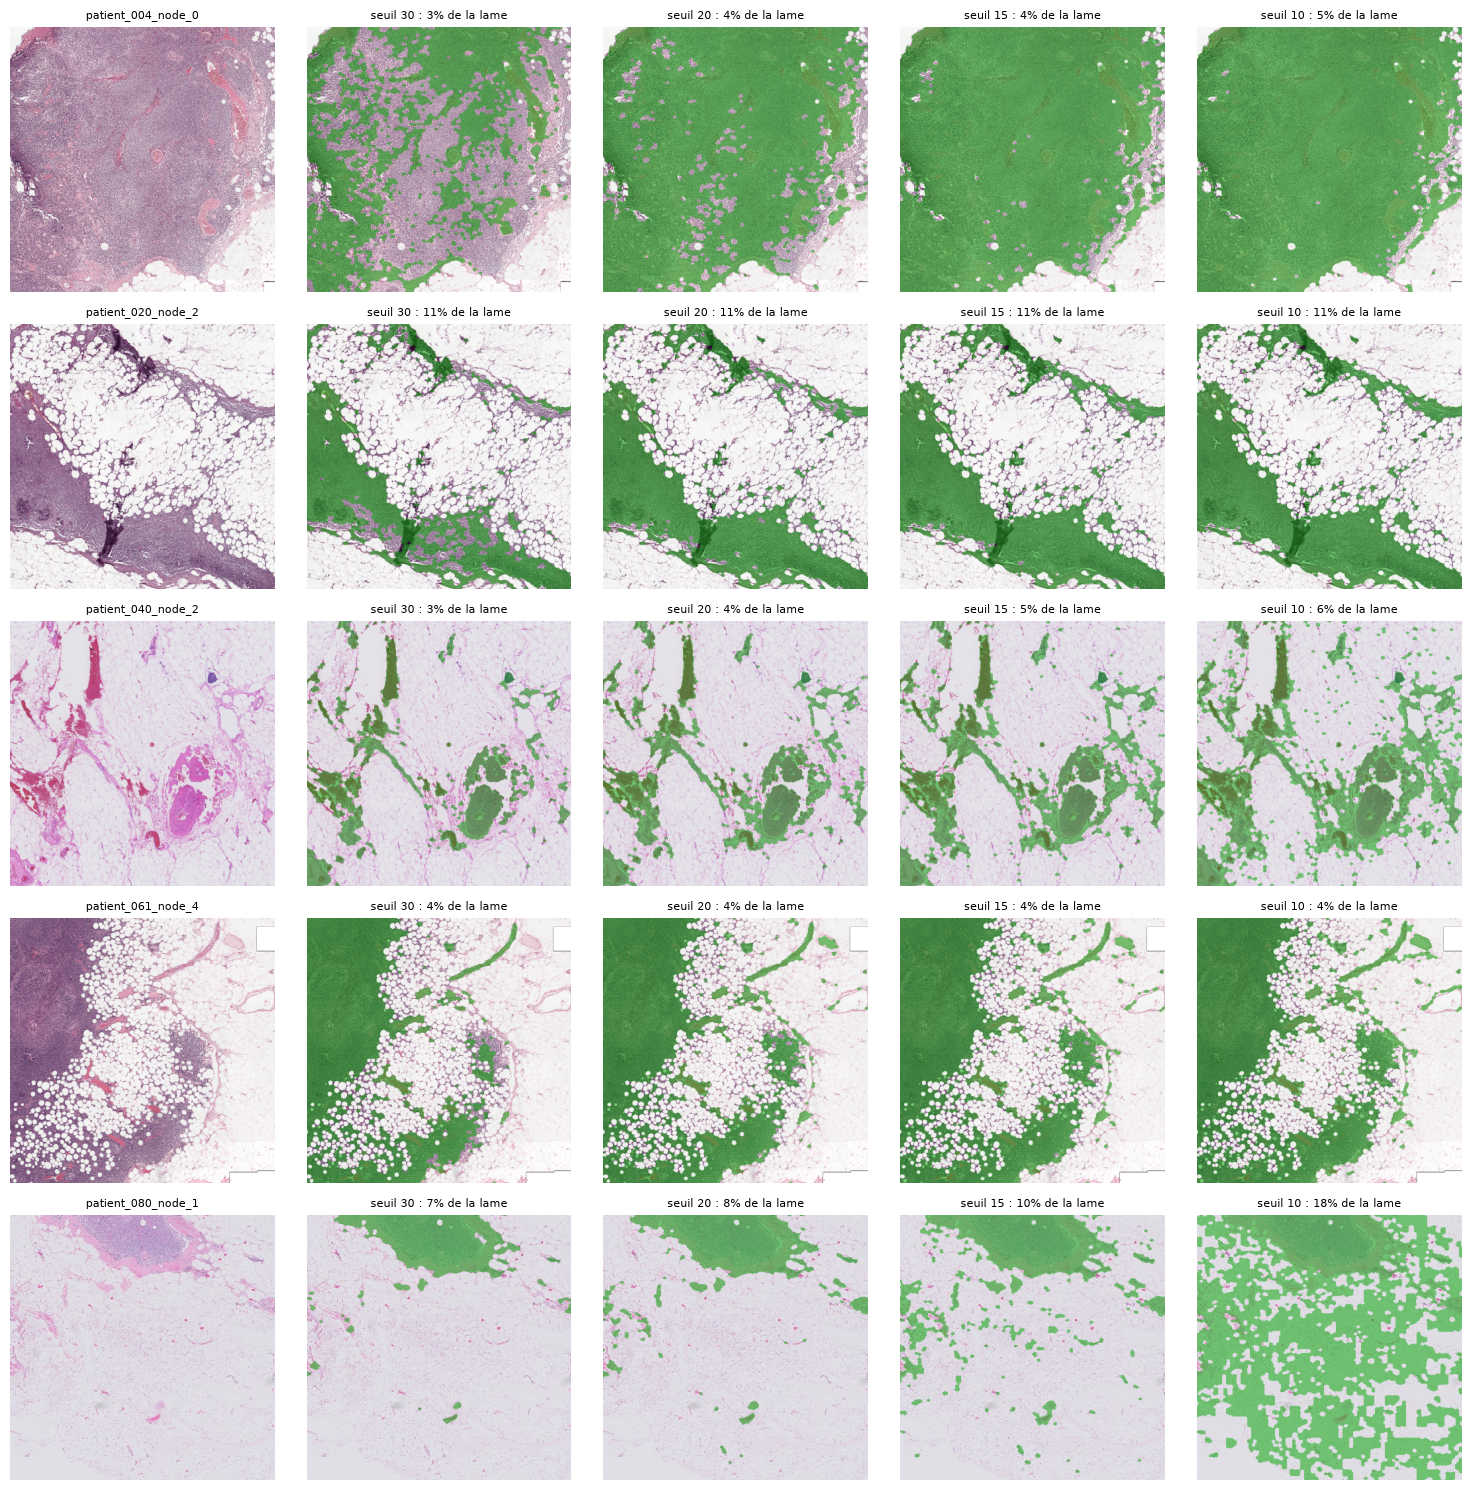

In [18]:
lames_vues = selection[selection.set == "entrainement"].groupby("center").slide.first()   # une lame par centre
seuils = [30, 20, 15, 10]
fig, axes = plt.subplots(len(lames_vues), len(seuils) + 1, figsize=(3 * (len(seuils) + 1), 3 * len(lames_vues)), squeeze=False)
for i, nom in enumerate(lames_vues):
    lame = index[index.slide == nom].iloc[0]
    slide = cd.open_slide(lame.tif_path)
    niveau = min(5, slide.level_count - 1)
    mini = np.asarray(cd.rgb_fond_blanc(slide.read_region((0, 0), niveau, slide.level_dimensions[niveau])))
    masques = {s: ep.detect_purple(mini, s) for s in seuils}

    # Zone du zoom : le carré de c x c pixels (environ 3 mm au niveau 5) où passer de 30 à 10 ajoute le plus de tissu
    c = min(400, *mini.shape[:2])
    ajoute = (masques[10] & ~masques[30]).astype(np.float32)
    densite = cv2.boxFilter(ajoute, -1, (c, c))          # part de tissu ajouté dans le carré centré sur chaque pixel
    y, x = np.unravel_index(np.argmax(densite), densite.shape)
    y0 = int(np.clip(y - c // 2, 0, mini.shape[0] - c))
    x0 = int(np.clip(x - c // 2, 0, mini.shape[1] - c))
    zone = (slice(y0, y0 + c), slice(x0, x0 + c))

    axes[i, 0].imshow(mini[zone])
    axes[i, 0].set_title(nom, fontsize=8)
    for j, s in enumerate(seuils, start=1):
        img = mini[zone].copy()
        garde = masques[s][zone]
        img[garde] = (0.5 * img[garde] + 0.5 * np.array([0, 170, 0])).astype(np.uint8)   # tissu gardé en vert
        axes[i, j].imshow(img)
        axes[i, j].set_title(f"seuil {s} : {masques[s].mean():.0%} de la lame", fontsize=8)
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()

On observe :
- Avec seuil 30 : le tissu du ganglion est troué (centre 0)
- Avec seuil 20 : encore quelques trous
- Avec seuil 15 : le ganglion est bien rempli et la graisse et le fond restent exclus
- Avec seuil 10 : le fond de la lame commence à être pris (centre 4)

## 5. Lancement des variantes


Les variantes sont dans `parametres_decoupage.py` (dictionnaire `VARIANTES`). Chacune ne change qu'une chose par rapport à la `base` :
- `base` : étiquetage "pourcentage" (tumeur >= 50 % du patch), niveau 1
- `centre` : étiquetage : tumeur dans la zone centrale de 56 µm
- `niveaux` : même surface (112 µm) lue au niveau 2

Les commandes se lancent dans un terminal, depuis le dossier `version_finale` :

```
python extract_patches.py --variante base centre niveaux
python extract_patches.py --variante centre --max-slides 2      (pour un essai rapide)
```

Chaque variante va dans `patches/<variante>/niveau_<n>/`.

## 6. Comparaison des variantes sur l'étiquetage


On relit les `patches.csv` de chaque variante et de chaque niveau.

In [6]:
tables = []
for csv in sorted(Path(pdc.PARAMETRES.get("out", "patches")).glob("*/niveau_*/patches.csv")):
    t = pd.read_csv(csv)
    t["variante"] = csv.parent.parent.name
    tables.append(t)
patchs = pd.concat(tables, ignore_index=True)
# On ajoute la classe de la lame (negative, itc, micro, macro) pour l'analyse
patchs = patchs.merge(index[["slide", "slide_label"]], on="slide", how="left")
patchs.groupby(["variante", "niveau", "set", "label"]).size().unstack(fill_value=0)

label                         normal  tumor
variante niveau set                        
base     1      entrainement    8525   1810
                validation      2388    531
centre   1      entrainement    8525   2050
                validation      2388    638
niveaux  2      entrainement    8598   1810
                validation      2428    531

### 6.1 Étiquetage : pourcentage ou centre

Avec "pourcentage", une petite lésion (plus petite que la moitié d'un patch) ne donne aucun patch "tumor". Avec "centre", elle en donne dès qu'elle touche la zone centrale. 

On compare donc le nombre de patchs tumoraux par classe de lame en fonction des deux variantes afin de choisir.

In [7]:
tumeur = patchs[(patchs.label == "tumor") & patchs.variante.isin(["base", "centre"])]
tumeur.groupby(["slide_label", "variante"]).size().unstack(fill_value=0)

variante,base,centre
slide_label,,
itc,7,51
macro,2202,2296
micro,132,341


In [8]:
# Lames annotées sans aucun patch tumoral : ce sont les lésions perdues
annotees = selection[selection.annotated & (selection.set != "test")].slide
for v in ["base", "centre"]:
    vues = set(tumeur[tumeur.variante == v].slide)
    print(v, ": lames annotées sans patch tumoral ->", sorted(set(annotees) - vues))

base : lames annotées sans patch tumoral -> ['patient_016_node_1', 'patient_017_node_1', 'patient_024_node_1', 'patient_024_node_2', 'patient_046_node_4', 'patient_060_node_3', 'patient_068_node_1', 'patient_072_node_0', 'patient_087_node_0', 'patient_089_node_3']
centre : lames annotées sans patch tumoral -> ['patient_068_node_1']


Les grosses lésions (macro) sont vues de la même façon par les deux méthodes mais pas pour les petites lésions. Avec "pourcentage", le modèle n'apprendrait presque rien sur les ITC notamment.

On choisit donc de garder l'étiquetage sur le centre du patch car l'étiquetage par pourcentage perd trop de lésions que notre option choisie garde.

### 6.2 Exemples de patchs

Le carré jaune montre la zone centrale (56 µm) qui sert à l'étiquetage par le centre.

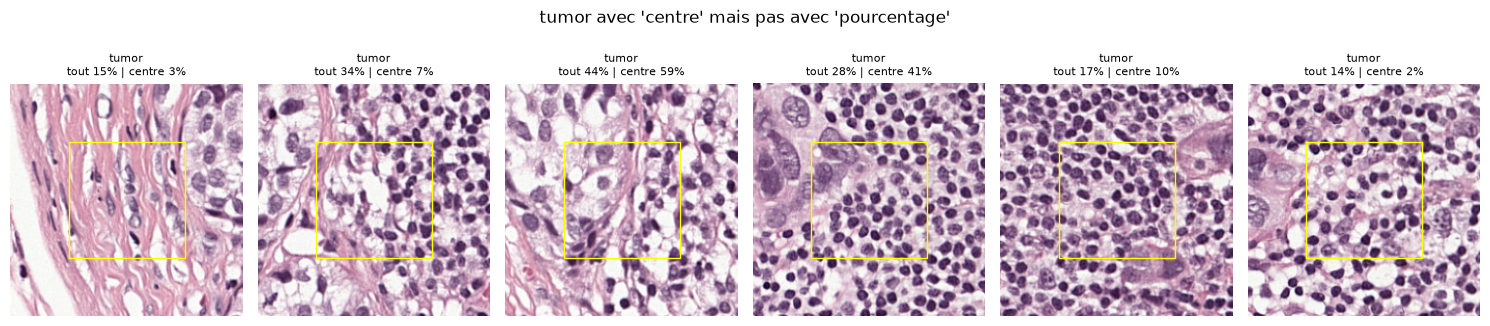

In [9]:
def image_patch(ligne):
    if isinstance(ligne.path, str) and ligne.path:
        return np.asarray(Image.open(ligne.path))
    slide = cd.open_slide(index[index.slide == ligne.slide].tif_path.iloc[0])
    img = cd.rgb_fond_blanc(slide.read_region((int(ligne.x), int(ligne.y)), int(ligne.niveau),
                                              (int(ligne.taille_lue), int(ligne.taille_lue))))
    return np.asarray(img.resize((224, 224)))

def montrer(lignes, titre):
    fig, axes = plt.subplots(1, len(lignes), figsize=(2.5 * len(lignes), 3), squeeze=False)
    for a, (_, l) in zip(axes[0], lignes.iterrows()):
        a.imshow(image_patch(l))
        c = 224 * pdc.PARAMETRES["centre_um"] / pdc.PARAMETRES["patch_um"]
        d = (224 - c) / 2
        a.add_patch(plt.Rectangle((d, d), c, c, fill=False, color="yellow"))
        a.set_title(f"{l.label}\ntout {l.tumor_frac:.0%} | centre {l.tumor_frac_centre:.0%}", fontsize=8)
        a.axis("off")
    fig.suptitle(titre, y=1.08)
    plt.tight_layout()

centre = patchs[patchs.variante == "centre"]
montrer(centre[(centre.label == "tumor") & (centre.tumor_frac < 0.5)].head(6), "tumor avec 'centre' mais pas avec 'pourcentage'")